# CLIP-SAFMOE: Semantic-Adaptive Fusion with Mixture-of-Emotion-Experts

**Novel Architecture for Facial Expression Recognition on RAF-DB**

Three novel contributions:
1. **Adaptive Scale Fusion (ASF)** — Input-dependent dynamic gating across 4 ViT layers
2. **Semantic Alignment Module (SAM)** — CLIP text encoder with AU-enriched prompts as attention conditioning
3. **Mixture-of-Emotion-Experts (MoEE) Decoder** — Soft-routed expert FFN networks in decoder

Target: Beat SOTA 92.5% on RAF-DB (7-class basic emotions)

In [ ]:
# %% Cell 1: Package installation
import importlib, subprocess, sys

def _ensure_packages(specs):
    """specs: list of (pip_spec, import_name). Installs only what is missing."""
    for spec, mod in specs:
        try:
            importlib.import_module(mod)
            print(f"[ok] {mod} already available")
        except ImportError:
            print(f"[install] {spec} ...")
            try:
                subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", spec])
                importlib.invalidate_caches()
                importlib.import_module(mod)
                print(f"[ok] installed {spec}")
            except Exception as e:
                print(f"[warn] could not install {spec}: {e}")

import torch

_ensure_packages([
    ("timm>=0.9.2", "timm"),
    ("albumentations>=1.3.0", "albumentations"),
    ("open_clip_torch>=2.20.0", "open_clip"),
])

try:
    import timm, open_clip
    print("timm:", timm.__version__)
    print("open_clip:", open_clip.__version__)
except ImportError as e:
    raise RuntimeError(
        f"`{e.name}` is unavailable. Enable Internet in Kaggle notebook settings "
        "(Session options -> Internet -> ON) and rerun this cell."
    )

[ok] timm already available
[ok] albumentations already available
[install] open_clip_torch>=2.20.0 ...
[ok] installed open_clip_torch>=2.20.0
timm: 1.0.29
open_clip: 3.3.0


In [ ]:
# %% Cell 2: Imports
import os, sys, gc, json, math, time, random, copy, warnings
from pathlib import Path
from collections import Counter, defaultdict
from dataclasses import dataclass, field, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cv2
cv2.setNumThreads(0)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import timm
import open_clip
import albumentations as A

try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

# GPU-first device selection (optimised for H100)
HAS_XLA = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# H100 perf: enable TF32 for float32 matmuls and cuDNN autotuner
if torch.cuda.is_available():
    torch.set_float32_matmul_precision("high")  # TF32 on Hopper
    torch.backends.cudnn.benchmark = True        # autotuner for fixed-size inputs

print("Python :", sys.version.split()[0])
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
print("Device :", DEVICE)

Python : 3.13.15
PyTorch: 2.11.0+cu128 | CUDA available: True
GPU    : NVIDIA RTX PRO 6000 Blackwell Server Edition
VRAM   : 95.0 GB
Device : cuda


In [ ]:
# %% Cell 3: Configuration
class CFG:
    # ---- reproducibility ------------------------------------------------
    seed              = 42
    # ---- data -----------------------------------------------------------
    img_size          = 224
    val_fraction      = 0.05
    num_workers       = 8                  # H100 is compute-hungry, feed it faster
    # ---- paths (Kaggle auto-detection) ----------------------------------
    input_roots       = [
        "/kaggle/input",
        os.environ.get("RAF_DB_DIR", ""),
    ]
    work_dir          = "/kaggle/working/safmoe_output"
    # ---- model ----------------------------------------------------------
    backbone          = "vit_large_patch14_clip_224.openai"  # CLIP ViT-L/14 (much stronger features)
    clip_model_name   = "ViT-L-14"          # for open_clip text encoder
    clip_pretrained   = "openai"            # pretrained weights source

    embed_dim         = 384                 # decoder/token internal width (wider for ViT-L)
    dec_depth         = 2                   # MoEE decoder blocks
    dec_heads         = 8
    dec_ff            = 1536
    token_grid        = 7                   # pooled tokens per scale
    hook_layers       = [6, 12, 18, 23]      # 4-scale for ViT-L/14 (24 blocks)
    drop_path_rate    = 0.20                # stochastic depth (higher for ViT-L)

    # ---- Novel 1: Adaptive Scale Fusion ---------------------------------
    use_asf           = True

    # ---- Novel 2: Semantic Alignment Module -----------------------------
    use_sam           = True
    sam_heads         = 4                   # cross-attention heads for SAM
    sam_depth         = 1                   # SAM cross-attention layers

    # ---- Novel 3: Mixture-of-Emotion-Experts ----------------------------
    use_moee          = True
    num_experts       = 5                   # expert FFN networks
    top_k_experts     = 2                   # active experts per query
    expert_load_balance_w = 0.01            # load balance loss weight

    # ---- Soft Region Tokenizer ------------------------------------------
    use_regions       = True
    num_regions       = 6                   # landmark-free soft regions

    # ---- LoRA -----------------------------------------------------------
    use_lora          = True
    lora_rank         = 16
    lora_alpha        = 32
    lora_blocks       = [16, 17, 18, 19, 20, 21, 22, 23]   # apply LoRA to top 8 blocks (ViT-L has 24)

    # ---- optimization ---------------------------------------------------
    batch_size        = 64                 # H100 80GB (ViT-L is larger)
    eval_batch_size   = 128                # H100 80GB (ViT-L is larger)
    epochs            = 80
    patience          = 20
    warmup_epochs     = 5                   # head-only warmup phase
    lr                = 3e-4                # head/decoder LR (higher for stronger features)
    lora_lr           = 2e-5                # LoRA adapter LR (lower for larger model)
    trunk_lr          = 0.0                 # trunk frozen (LoRA handles adaptation)
    weight_decay      = 4e-2
    min_lr_ratio      = 0.01
    grad_clip         = 1.0
    ema_decay         = 0.9995              # tighter EMA for self-distillation
    use_amp           = True
    llrd              = 0.75                # layer-wise LR decay (for LoRA blocks)

    # ---- loss -----------------------------------------------------------
    label_smoothing   = 0.10
    focal_gamma       = 1.5                 # mild focal modulation
    use_class_weights = True
    balance_power     = 0.5                 # sqrt-weighted class balance

    # main loss weights
    aux_global_w      = 0.15                # auxiliary CLS head weight
    aux_region_w      = 0.10                # auxiliary region head weight

    # contrastive & margin losses
    supcon_w          = 0.03
    supcon_temp       = 0.12
    hinge_w           = 0.10
    hinge_margin      = 0.35

    # Novel 2: Semantic alignment loss
    sem_align_w       = 0.08

    # EMA consistency regularization
    consistency_w     = 0.05
    consistency_start = 5                   # start epoch

    # ---- Label Distribution Learning (LDL) ------------------------------
    use_ldl           = True
    ldl_start_epoch   = 8
    ldl_alpha         = 0.8                 # 80% hard + 20% soft
    ldl_temperature   = 4.0
    ldl_ramp_epochs   = 5

    # ---- CutMix ---------------------------------------------------------
    cutmix_alpha      = 0.3
    cutmix_prob       = 0.5                 # probability of applying CutMix per batch

    # ---- task constants --------------------------------------------------
    num_classes       = 7
    CLASS_NAMES = ["surprise", "fear", "disgust", "happiness", "sadness", "anger", "neutral"]
    CONFUSABLE_PAIRS = [(0, 1), (2, 5), (4, 6), (6, 3)]  # fear↔surprise, disgust↔anger, sad↔neutral, neutral↔happy

    # AU-enriched text prompts for SAM (Novel 2)
    EMOTION_PROMPTS = [
        "A face showing surprise: raised eyebrows, wide open eyes, dropped jaw, open mouth",
        "A face showing fear: raised inner brows, wide eyes, stretched lips horizontally, tense lower eyelid",
        "A face showing disgust: wrinkled nose, raised upper lip, lowered brows, narrowed eyes",
        "A face showing happiness: raised cheeks, crow's feet wrinkles, lip corners pulled up, exposed teeth",
        "A face showing sadness: inner brows raised, lip corners pulled down, chin dimpled, drooping upper eyelids",
        "A face showing anger: lowered brows, tightened lower eyelids, lips pressed together, dilated nostrils",
        "A face showing neutral expression: relaxed facial muscles, neutral mouth, normal eye opening, no brow movement",
    ]

    # CLIP normalization
    MEAN = [0.48145466, 0.4578275, 0.40821073]   # CLIP standard
    STD  = [0.26862954, 0.26130258, 0.27577711]

    # reference baselines
    poster_acc     = 92.05
    poster_pp_acc  = 92.21
    clip_sota_acc  = 92.50
    agent_poster   = 92.61

    resume_path    = ""

os.makedirs(CFG.work_dir, exist_ok=True)
BEST_PATH    = os.path.join(CFG.work_dir, "best_safmoe.pt")
LAST_PATH    = os.path.join(CFG.work_dir, "last_safmoe.pt")
PRED_CSV     = os.path.join(CFG.work_dir, "predictions.csv")
METRICS_JSON = os.path.join(CFG.work_dir, "metrics.json")
print(f"Work dir: {CFG.work_dir}")

Work dir: /kaggle/working/safmoe_output


In [ ]:
# %% Cell 4: Reproducibility
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = False  # H100: speed over bit-exact repro
        torch.backends.cudnn.benchmark = True        # H100: autotuner for fixed shapes

seed_everything(CFG.seed)
print(f"Seed set to {CFG.seed}")

# AMP context (H100: use BF16 for better range + speed on Hopper Tensor Cores)
if CFG.use_amp and DEVICE.type == "cuda":
    autocast_ctx = lambda: torch.amp.autocast("cuda", dtype=torch.bfloat16)
    # BF16 does not need loss scaling — disable GradScaler
    SCALER = torch.amp.GradScaler("cuda", enabled=False)
else:
    from contextlib import nullcontext
    autocast_ctx = nullcontext
    SCALER = torch.amp.GradScaler(enabled=False)
print(f"AMP: {'ON' if CFG.use_amp and DEVICE.type == 'cuda' else 'OFF'}")

Seed set to 42
AMP: ON


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# %% Cell 5: RAF-DB Specific Data Loading & Integrity Checks
import os
import zipfile
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import cv2
import numpy as np
import glob

print("Searching for RAF-DB dataset...")
LABEL_FILE = None
ALIGNED_ZIP = None

def find_file(name_substrings, start_dir="/content"):
    for root, dirs, files in os.walk(start_dir):
        # Skip hidden directories and virtual envs to speed up search
        dirs[:] = [d for d in dirs if not d.startswith('.') and d not in ['__pycache__', 'sample_data']]
        for f in files:
            if any(sub.lower() in f.lower() for sub in name_substrings):
                return os.path.join(root, f)
    return None

LABEL_FILE = find_file(["list_patition", "list_partition", "label.txt"])
ALIGNED_ZIP = find_file(["aligned.zip"])

# Check if they just uploaded the master zip file and haven't extracted it
if not LABEL_FILE:
    print("Could not find extracted RAF-DB label files. Checking for base zip files...")
    base_zip = find_file(["rafdb.zip", "raf-db.zip", "basic.zip", "raf_db.zip", "fer.zip"])
    if base_zip:
        print(f"Found base zip: {base_zip}. Extracting to /content/RAFDB_extracted/ ...")
        os.makedirs("/content/RAFDB_extracted/", exist_ok=True)
        with zipfile.ZipFile(base_zip, 'r') as z:
            z.extractall("/content/RAFDB_extracted/")
        # Try finding again
        LABEL_FILE = find_file(["list_patition", "list_partition", "label.txt"], start_dir="/content/RAFDB_extracted/")
        ALIGNED_ZIP = find_file(["aligned.zip"], start_dir="/content/RAFDB_extracted/")

if not LABEL_FILE:
    print("\n❌ FATAL ERROR: Dataset not found.")
    print("Here are the files currently in /content/:")
    for root, dirs, files in os.walk("/content/"):
        dirs[:] = [d for d in dirs if not d.startswith('.') and d not in ['sample_data']]
        for f in files:
            print(f" - {os.path.join(root, f)}")

    assert False, "Could not find 'list_patition_label.txt'. Please upload the RAF-DB dataset (or a zip containing it) to Colab."

print(f"Found Label File: {LABEL_FILE}")

EXTRACT_DIR = "/content/RAFDB_aligned_images/"

# Determine if we need to extract aligned.zip or if the images are already unzipped
if ALIGNED_ZIP and os.path.exists(ALIGNED_ZIP):
    print(f"Found Aligned Zip: {ALIGNED_ZIP}")
    if not os.path.exists(EXTRACT_DIR) or len(os.listdir(EXTRACT_DIR)) == 0:
        print(f"Extracting {ALIGNED_ZIP} to {EXTRACT_DIR}...")
        os.makedirs(EXTRACT_DIR, exist_ok=True)
        with zipfile.ZipFile(ALIGNED_ZIP, 'r') as zip_ref:
            zip_ref.extractall(EXTRACT_DIR)
    else:
        print(f"Dataset already extracted to {EXTRACT_DIR}")

    IMAGE_SEARCH_DIR = EXTRACT_DIR
else:
    print("No aligned.zip found. Assuming images are already unzipped in folders.")
    # Search for a folder with lots of images near the label file
    base_search = os.path.dirname(os.path.dirname(LABEL_FILE))
    IMAGE_SEARCH_DIR = base_search

# 2. Find actual image directory programmatically
IMAGE_DIR = None
for root, dirs, files in os.walk(IMAGE_SEARCH_DIR):
    if len([f for f in files if f.endswith(('.jpg', '.jpeg', '.png', '.bmp'))]) > 100:
        IMAGE_DIR = root
        break

assert IMAGE_DIR is not None, f"Could not find a directory with images inside {IMAGE_SEARCH_DIR}"
print(f"Final image directory: {IMAGE_DIR}")

# 3. Parse labels and create dataframes
records = {"train": [], "test": []}
missing = 0
found = 0

available_files = set(os.listdir(IMAGE_DIR))

def resolve_img_file(base_name):
    if base_name in available_files: return base_name
    stem = Path(base_name).stem
    ext = Path(base_name).suffix
    aligned_name = f"{stem}_aligned{ext}"
    if aligned_name in available_files: return aligned_name
    return None

with open(LABEL_FILE, "r") as f:
    for line in f:
        line = line.strip()
        if not line: continue
        parts = line.split()
        if len(parts) != 2: continue

        filename, label_str = parts[0], parts[1]
        label = int(label_str) - 1 # PyTorch expects 0-6

        actual_filename = resolve_img_file(filename)
        if actual_filename:
            full_path = os.path.join(IMAGE_DIR, actual_filename)
            split = "train" if filename.startswith("train") else "test"
            records[split].append((full_path, label))
            found += 1
        else:
            missing += 1

TRAIN_DF_ALL = pd.DataFrame(records["train"], columns=["filepath", "label"]).sample(frac=1.0, random_state=CFG.seed).reset_index(drop=True)
TEST_DF = pd.DataFrame(records["test"], columns=["filepath", "label"]).sample(frac=1.0, random_state=CFG.seed).reset_index(drop=True)
HAS_OFFICIAL_TEST = len(TEST_DF) > 0

def stratified_split(df, val_fraction, seed):
    rng = np.random.default_rng(seed)
    val_idx = set()
    for c in sorted(df.label.unique()):
        idx = df.index[df.label == c].to_numpy().copy()
        rng.shuffle(idx)
        k = max(1, int(round(val_fraction * len(idx))))
        val_idx.update(idx[:k].tolist())
    mask = df.index.isin(val_idx)
    return df[~mask].reset_index(drop=True), df[mask].reset_index(drop=True)

FIT_DF, VAL_DF = stratified_split(TRAIN_DF_ALL, CFG.val_fraction, CFG.seed)
NUM_CLASSES = CFG.num_classes

print("\n--- Dataset Statistics ---")
print(f"Total images found: {found}")
print(f"Missing images: {missing}")
print(f"Train split (all): {len(TRAIN_DF_ALL)} (used for fit: {len(FIT_DF)}, val: {len(VAL_DF)})")
print(f"Test split: {len(TEST_DF)}")

print("\nClass Distribution (Train All):")
dist = TRAIN_DF_ALL['label'].value_counts().sort_index()
for c, count in dist.items():
    print(f"  {CFG.CLASS_NAMES[c]} ({c}): {count}")



Searching for RAF-DB dataset...
Could not find extracted RAF-DB label files. Checking for base zip files...
Found base zip: /content/drive/MyDrive/Anjimoon/DATA SETS/RAF-DB_Original_basic.zip. Extracting to /content/RAFDB_extracted/ ...
Found Label File: /content/RAFDB_extracted/RAF-DB_Original_basic/list_patition_label.txt
No aligned.zip found. Assuming images are already unzipped in folders.
Final image directory: /content/RAFDB_extracted/RAF-DB_Original_basic/aligned

--- Dataset Statistics ---
Total images found: 15339
Missing images: 0
Train split (all): 12271 (used for fit: 11658, val: 613)
Test split: 3068

Class Distribution (Train All):
  surprise (0): 1290
  fear (1): 281
  disgust (2): 717
  happiness (3): 4772
  sadness (4): 1982
  anger (5): 705
  neutral (6): 2524


Displaying a few random samples from the training set to verify data loader is correct...


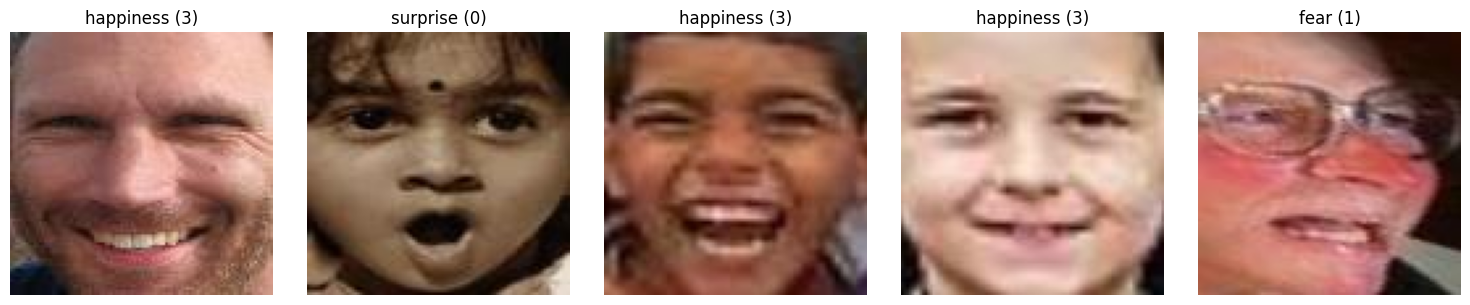

In [ ]:
# %% Cell 6: Data Visualization Verification
print("Displaying a few random samples from the training set to verify data loader is correct...")
sample_df = FIT_DF.sample(min(5, len(FIT_DF)))
fig, axes = plt.subplots(1, len(sample_df), figsize=(15, 3))
if len(sample_df) == 1: axes = [axes]

for ax, (_, row) in zip(axes, sample_df.iterrows()):
    img = cv2.imread(row['filepath'])
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img)
    ax.set_title(f"{CFG.CLASS_NAMES[row['label']]} ({row['label']})")
    ax.axis('off')
plt.tight_layout()
plt.show()



In [ ]:
# %% Cell 7: Augmentation Pipeline
_MEAN = np.array(CFG.MEAN, dtype=np.float32)
_STD  = np.array(CFG.STD, dtype=np.float32)

def _normalize(image, **kw):
    return ((image.astype(np.float32) / 255.0 - _MEAN) / _STD).astype(np.float32)

def _try(cls, **kw):
    try: return cls(**kw)
    except (TypeError, AttributeError): return A.NoOp()

TRAIN_TFMS = A.Compose([
    A.Resize(CFG.img_size, CFG.img_size),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.06, scale_limit=0.12, rotate_limit=12,
                       border_mode=0, p=0.5),
    A.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.05, p=0.5),
    _try(A.CoarseDropout, max_holes=1, max_height=int(CFG.img_size*0.25),
         max_width=int(CFG.img_size*0.25), fill_value=128, p=0.3),
    A.GaussNoise(var_limit=(5, 25), p=0.2),
    A.Lambda(image=_normalize),
])

EVAL_TFMS = A.Compose([
    A.Resize(CFG.img_size, CFG.img_size),
    A.Lambda(image=_normalize),
])

# 8-view TTA
_s = CFG.img_size
_z = int(round(_s * 1.14))
_norm = A.Lambda(image=_normalize)

TTA_VIEWS = [
    A.Compose([A.Resize(_s, _s), _norm]),
    A.Compose([A.Resize(_s, _s), A.HorizontalFlip(p=1.0), _norm]),
    A.Compose([A.Resize(_z, _z), A.CenterCrop(_s, _s), _norm]),
    A.Compose([A.Resize(_z, _z), A.CenterCrop(_s, _s), A.HorizontalFlip(p=1.0), _norm]),
    A.Compose([A.Resize(_s, _s), A.ColorJitter(brightness=(1.1, 1.1), contrast=0.0, saturation=0.0, hue=0.0, p=1.0), _norm]),
    A.Compose([A.Resize(_s, _s), A.ColorJitter(brightness=(0.9, 0.9), contrast=0.0, saturation=0.0, hue=0.0, p=1.0), _norm]),
    A.Compose([A.Resize(_s, _s), A.ColorJitter(brightness=0.0, contrast=(1.1, 1.1), saturation=0.0, hue=0.0, p=1.0), _norm]),
    A.Compose([A.Resize(_s, _s), A.ColorJitter(brightness=0.0, contrast=(0.9, 0.9), saturation=0.0, hue=0.0, p=1.0), _norm]),
]

print(f"Augmentations ready: {len(TTA_VIEWS)}-view TTA")

Augmentations ready: 8-view TTA


In [ ]:
# %% Cell 8: Dataset & DataLoader
class RafDataset(Dataset):
    """Returns (float_tensor CHW RGB-normalised, long label)."""
    def __init__(self, df, tfms=None):
        self.paths  = df.filepath.tolist()
        self.labels = df.label.astype(np.int64).tolist()
        self.tfms   = tfms
        self.bad    = 0

    def __len__(self):
        return len(self.paths)

    def _read(self, path):
        img = cv2.imread(path, cv2.IMREAD_COLOR)
        if img is None:
            try:
                from PIL import Image
                pil = Image.open(path).convert("RGB")
                img = cv2.cvtColor(np.asarray(pil), cv2.COLOR_RGB2BGR)
            except Exception:
                self.bad += 1
                img = np.zeros((CFG.img_size, CFG.img_size, 3), dtype=np.uint8)
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    def __getitem__(self, idx):
        img = self._read(self.paths[idx])
        if self.tfms:
            img = self.tfms(image=img)["image"]
        img = torch.from_numpy(img).permute(2, 0, 1)  # HWC -> CHW
        return img, self.labels[idx]

def make_loader(df, tfms, train=True, bs=None):
    ds = RafDataset(df, tfms)
    bs = bs or (CFG.batch_size if train else CFG.eval_batch_size)
    return DataLoader(ds, batch_size=bs, shuffle=train, num_workers=CFG.num_workers,
                      pin_memory=True, drop_last=train, persistent_workers=CFG.num_workers > 0)

TRAIN_LOADER = make_loader(FIT_DF, TRAIN_TFMS, train=True)
VAL_LOADER   = make_loader(VAL_DF, EVAL_TFMS, train=False)
STEPS_PER_EPOCH = len(TRAIN_LOADER)
print(f"Train batches/epoch: {STEPS_PER_EPOCH} | Val batches: {len(VAL_LOADER)}")

Train batches/epoch: 182 | Val batches: 5


## Novel Architecture Components

### Novel 1: Adaptive Scale Fusion (ASF)
Input-adaptive gating across 4 ViT layers — each image gets its own layer importance weights.

### Novel 2: Semantic Alignment Module (SAM)  
CLIP text encoder generates AU-enriched emotion anchors; visual tokens cross-attend to them.

### Novel 3: Mixture-of-Emotion-Experts (MoEE) Decoder
Replaces standard FFN with soft-routed expert networks — first application of MoE in FER decoders.

In [ ]:
# %% Cell 9: LoRA Adapter
class LoRALinear(nn.Module):
    """Low-Rank Adaptation for linear layers. Wraps an existing nn.Linear."""
    def __init__(self, original: nn.Linear, rank=8, alpha=16):
        super().__init__()
        self.original = original
        self.rank = rank
        self.alpha = alpha
        self.scaling = alpha / rank

        in_f, out_f = original.in_features, original.out_features
        # Freeze original
        for p in self.original.parameters():
            p.requires_grad_(False)

        # Low-rank decomposition
        self.lora_A = nn.Parameter(torch.randn(in_f, rank) * 0.01)
        self.lora_B = nn.Parameter(torch.zeros(rank, out_f))

    def forward(self, x):
        # Original (frozen) + LoRA adaptation
        result = self.original(x)
        lora_out = (x @ self.lora_A @ self.lora_B) * self.scaling
        return result + lora_out


def inject_lora(model, target_blocks, rank=8, alpha=16):
    """Inject LoRA adapters into qkv projections of specified ViT blocks."""
    count = 0
    for bi in target_blocks:
        if bi >= len(model.blocks):
            continue
        block = model.blocks[bi]
        attn = block.attn
        # Replace qkv projection
        if hasattr(attn, 'qkv') and isinstance(attn.qkv, nn.Linear):
            attn.qkv = LoRALinear(attn.qkv, rank=rank, alpha=alpha)
            count += 1
        # Replace proj (output projection)
        if hasattr(attn, 'proj') and isinstance(attn.proj, nn.Linear):
            attn.proj = LoRALinear(attn.proj, rank=rank, alpha=alpha)
            count += 1
    lora_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"[LoRA] Injected into {count} layers | rank={rank} alpha={alpha} | "
          f"trainable LoRA params: {lora_params/1e3:.1f}K")
    return model

In [ ]:
# %% Cell 10: Soft Region Tokenizer (landmark-free)
def gaussian_map(h, w, cy, cx, sy, sx, device, dtype):
    yy = torch.linspace(0, 1, h, device=device, dtype=dtype).view(h, 1)
    xx = torch.linspace(0, 1, w, device=device, dtype=dtype).view(1, w)
    return torch.exp(-0.5 * (((yy - cy) / sy) ** 2 + ((xx - cx) / sx) ** 2))


class SoftRegionTokenizer(nn.Module):
    """Landmark-free soft regions with Gaussian spatial priors.

    Produces K region tokens from feature maps without requiring face landmarks.
    Gaussian priors encode anatomical knowledge (eyes, nose, mouth positions).
    """
    def __init__(self, dim, num_regions=6):
        super().__init__()
        self.k = num_regions
        self.attn_logits = nn.Sequential(
            nn.Conv2d(dim, dim // 4, 1), nn.GELU(),
            nn.Conv2d(dim // 4, num_regions, 1)
        )
        nn.init.zeros_(self.attn_logits[-1].weight)
        nn.init.zeros_(self.attn_logits[-1].bias)
        self.prior_strength = nn.Parameter(torch.tensor(1.25))
        self.token_norm = nn.LayerNorm(dim)

    def coordinate_priors(self, h, w, device, dtype):
        # Anatomical region centers: (cy, cx, sy, sx)
        specs = [
            (0.32, 0.50, 0.12, 0.30),   # eyes/brows
            (0.45, 0.50, 0.10, 0.15),   # nose bridge
            (0.65, 0.50, 0.12, 0.25),   # mouth
            (0.50, 0.28, 0.18, 0.15),   # left cheek
            (0.50, 0.72, 0.18, 0.15),   # right cheek
            (0.80, 0.50, 0.12, 0.20),   # chin
        ]
        maps = []
        for cy, cx, sy, sx in specs[:self.k]:
            maps.append(gaussian_map(h, w, cy, cx, sy, sx, device, dtype))
        return torch.stack(maps, dim=0)  # (K, H, W)

    def forward(self, feat_map):
        """
        Args:
            feat_map: (B, C, H, W)
        Returns:
            region_tokens: (B, K, C)
        """
        B, C, H, W = feat_map.shape
        logits = self.attn_logits(feat_map)  # (B, K, H, W)

        priors = self.coordinate_priors(H, W, feat_map.device, feat_map.dtype)
        log_priors = torch.log(priors.clamp(1e-6)).unsqueeze(0)  # (1, K, H, W)
        strength = self.prior_strength.clamp(0.1, 3.0)
        logits = logits + strength * log_priors

        attn = torch.softmax(logits.flatten(2), dim=-1)  # (B, K, H*W)
        feat_flat = feat_map.flatten(2)  # (B, C, H*W)
        tokens = torch.bmm(attn, feat_flat.transpose(1, 2))  # (B, K, C)
        return self.token_norm(tokens)

In [ ]:
# %% Cell 11: Novel 1 — Adaptive Scale Fusion (ASF)
class AdaptiveScaleFusion(nn.Module):
    """Input-adaptive dynamic gating across multiple ViT layers.

    NOVEL CONTRIBUTION: Unlike static concatenation or learned-but-fixed weights,
    ASF produces per-image, per-layer importance weights. The CLS token serves as
    the routing signal — its semantic content determines which layers are most
    informative for each specific input image.

    For occluded faces, deeper semantic layers get higher weight.
    For clear micro-expressions, shallow texture layers get higher weight.
    """
    def __init__(self, num_layers, d_in, d_out):
        super().__init__()
        self.num_layers = num_layers
        # Gating network: CLS token -> per-layer importance
        self.gate = nn.Sequential(
            nn.Linear(d_in, d_in // 2),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(d_in // 2, num_layers),
        )
        # Per-layer projection to common dimension
        self.projections = nn.ModuleList([
            nn.Sequential(nn.LayerNorm(d_in), nn.Linear(d_in, d_out))
            for _ in range(num_layers)
        ])
        # Temperature for softmax sharpness (learnable)
        self.temperature = nn.Parameter(torch.tensor(1.0))

    def forward(self, cls_token, layer_token_lists):
        """
        Args:
            cls_token: (B, D) — CLS token as routing signal
            layer_token_lists: list of (B, N_i, D) — tokens from each layer
        Returns:
            fused_tokens: (B, N, d_out) — dynamically fused tokens
        """
        # Compute per-layer gates
        temp = self.temperature.clamp(0.1, 5.0)
        gate_logits = self.gate(cls_token) / temp  # (B, num_layers)
        gate_weights = torch.softmax(gate_logits, dim=-1)  # (B, num_layers)

        # Project and weight each layer's tokens
        B = cls_token.shape[0]
        # All layers are pooled to same spatial size, so N_i should be equal
        projected = []
        for i, (proj, tokens) in enumerate(zip(self.projections, layer_token_lists)):
            w = gate_weights[:, i].unsqueeze(1).unsqueeze(2)  # (B, 1, 1)
            projected.append(w * proj(tokens))

        # Sum weighted projections
        fused = sum(projected)  # (B, N, d_out)
        return fused, gate_weights

In [ ]:
# %% Cell 12: Novel 2 — Semantic Alignment Module (SAM)
class SemanticAlignmentModule(nn.Module):
    """Cross-attend visual tokens with CLIP text emotion anchors.

    NOVEL CONTRIBUTION: While CLIPER/Exp-CLIP use text features for zero-shot
    classification, SAM uses them as *attention conditioning* — the text anchors
    tell the decoder WHAT to look for in the visual tokens. The text features are
    frozen (from CLIP text encoder) but the cross-attention is fully learned.

    This creates semantically-grounded emotion features that combine:
    - Visual evidence (what the face looks like)
    - Semantic guidance (what each emotion should look like)
    """
    def __init__(self, d_visual, d_text, d_out, n_heads=4, depth=1, dropout=0.1):
        super().__init__()
        self.proj_text = nn.Linear(d_text, d_out)  # align text dim to model dim
        self.proj_visual = nn.Linear(d_visual, d_out)

        # Learnable cross-attention: visual queries attend to text keys/values
        layers = []
        for _ in range(depth):
            layer = nn.TransformerDecoderLayer(
                d_model=d_out, nhead=n_heads,
                dim_feedforward=d_out * 2,
                dropout=dropout, activation="gelu",
                batch_first=True, norm_first=True,
            )
            layers.append(layer)
        self.cross_attn = nn.ModuleList(layers)
        self.norm = nn.LayerNorm(d_out)

    def forward(self, visual_tokens, text_anchors):
        """
        Args:
            visual_tokens: (B, N_vis, d_visual)
            text_anchors: (1, 7, d_text) — frozen CLIP text embeddings, shared across batch
        Returns:
            sem_tokens: (B, 7, d_out) — semantically-grounded emotion tokens
        """
        B = visual_tokens.shape[0]
        # Project to common space
        memory = self.proj_visual(visual_tokens)  # (B, N, d_out)
        tgt = self.proj_text(text_anchors).expand(B, -1, -1)  # (B, 7, d_out)

        # Cross-attend: emotion text queries attend to visual memory
        for layer in self.cross_attn:
            tgt = layer(tgt, memory)

        return self.norm(tgt)  # (B, 7, d_out)

In [ ]:
# %% Cell 13: Novel 3 — Mixture-of-Emotion-Experts (MoEE)
class ExpertFFN(nn.Module):
    """A single expert FFN network."""
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)


class MoELayer(nn.Module):
    """Mixture-of-Experts layer with soft gating and load balancing.

    NOVEL CONTRIBUTION: First application of MoE in FER decoders. Different
    emotions have fundamentally different visual patterns (happiness = mouth+cheeks
    vs. fear = eyes+brows). A single FFN can't specialize, but with MoE,
    different emotions naturally learn to use different expert combinations.

    Uses top-K routing with soft gating (not hard switches) for stable training.
    """
    def __init__(self, d_model, d_ff, num_experts=5, top_k=2, dropout=0.1):
        super().__init__()
        self.num_experts = num_experts
        self.top_k = top_k

        # Expert networks
        self.experts = nn.ModuleList([
            ExpertFFN(d_model, d_ff, dropout) for _ in range(num_experts)
        ])

        # Router (gating network)
        self.router = nn.Linear(d_model, num_experts)

        # For load balancing loss tracking
        self._last_load_balance_loss = 0.0

    def forward(self, x):
        """
        Args:
            x: (B, N, D) — input tokens (N=7 emotion queries)
        Returns:
            output: (B, N, D)
        """
        B, N, D = x.shape

        # Compute routing scores
        router_logits = self.router(x)  # (B, N, num_experts)
        router_probs = torch.softmax(router_logits, dim=-1)  # (B, N, num_experts)

        # Top-K selection
        top_k_probs, top_k_indices = torch.topk(router_probs, self.top_k, dim=-1)
        # Re-normalize top-K probs
        top_k_probs = top_k_probs / (top_k_probs.sum(dim=-1, keepdim=True) + 1e-8)

        # Compute expert outputs (only for selected experts — but for simplicity
        # and gradient flow, we compute all and mask)
        expert_outputs = torch.stack([expert(x) for expert in self.experts], dim=2)
        # expert_outputs: (B, N, num_experts, D)

        # Gather selected expert outputs
        top_k_indices_expanded = top_k_indices.unsqueeze(-1).expand(-1, -1, -1, D)
        selected_outputs = torch.gather(expert_outputs, 2, top_k_indices_expanded)
        # selected_outputs: (B, N, top_k, D)

        # Weighted combination
        output = (top_k_probs.unsqueeze(-1) * selected_outputs).sum(dim=2)  # (B, N, D)

        # Compute load balancing loss (for training)
        if self.training:
            # Average routing probability per expert across all tokens
            avg_prob = router_probs.mean(dim=(0, 1))  # (num_experts,)
            # Fraction of tokens routed to each expert
            expert_mask = torch.zeros_like(router_probs)
            expert_mask.scatter_(2, top_k_indices, 1.0)
            avg_load = expert_mask.mean(dim=(0, 1))  # (num_experts,)
            # Load balance loss: encourages uniform expert usage
            self._last_load_balance_loss = ((avg_prob * avg_load).sum() * self.num_experts).clone()

        return output


class MoEEmotionDecoder(nn.Module):
    """Emotion Query Decoder with Mixture-of-Experts FFN.

    Architecture:
    1. 7 learnable emotion queries cross-attend to visual token memory
    2. MoE layer replaces standard FFN (Novel 3)
    3. Self-attention between queries models inter-emotion relationships
    4. Per-query logits via cosine similarity with class weights
    """
    def __init__(self, d=256, n_cls=7, n_tokens=148, depth=2, heads=8,
                 ffn_dim=1024, num_experts=5, top_k=2, drop=0.1):
        super().__init__()
        self.depth = depth
        self.n_cls = n_cls

        # Learnable emotion queries
        self.queries = nn.Parameter(torch.randn(1, n_cls, d) * 0.02)
        self.pos     = nn.Parameter(torch.zeros(1, n_tokens, d))

        # Per-layer modules
        self.cross_attns = nn.ModuleList()
        self.self_attns  = nn.ModuleList()
        self.moe_layers  = nn.ModuleList()
        self.norms_ca    = nn.ModuleList()  # pre-norm for cross-attn
        self.norms_sa    = nn.ModuleList()  # pre-norm for self-attn
        self.norms_ff    = nn.ModuleList()  # pre-norm for FFN/MoE

        for _ in range(depth):
            # Cross-attention: queries attend to visual memory
            self.cross_attns.append(
                nn.MultiheadAttention(d, heads, dropout=drop, batch_first=True)
            )
            # Self-attention: queries attend to each other
            self.self_attns.append(
                nn.MultiheadAttention(d, heads, dropout=drop, batch_first=True)
            )
            # MoE FFN (Novel 3)
            self.moe_layers.append(
                MoELayer(d, ffn_dim, num_experts=num_experts, top_k=top_k, dropout=drop)
            )
            self.norms_ca.append(nn.LayerNorm(d))
            self.norms_sa.append(nn.LayerNorm(d))
            self.norms_ff.append(nn.LayerNorm(d))

        self.norm_out = nn.LayerNorm(d)
        # Logit head: cosine similarity style
        self.w_cls = nn.Parameter(torch.randn(n_cls, d) * 0.02)
        self.b_cls = nn.Parameter(torch.zeros(n_cls))

    def forward(self, mem):
        """
        Args:
            mem: (B, N_tokens, D) — visual token memory
        Returns:
            query_out: (B, 7, D) — decoded emotion representations
            logits: (B, 7) — per-class logits
        """
        mem = mem + self.pos
        tgt = self.queries.expand(mem.size(0), -1, -1)

        for i in range(self.depth):
            # Pre-norm cross-attention
            tgt_norm = self.norms_ca[i](tgt)
            ca_out, _ = self.cross_attns[i](tgt_norm, mem, mem)
            tgt = tgt + ca_out

            # Pre-norm self-attention
            tgt_norm = self.norms_sa[i](tgt)
            sa_out, _ = self.self_attns[i](tgt_norm, tgt_norm, tgt_norm)
            tgt = tgt + sa_out

            # Pre-norm MoE FFN
            tgt_norm = self.norms_ff[i](tgt)
            moe_out = self.moe_layers[i](tgt_norm)
            tgt = tgt + moe_out

        tgt = self.norm_out(tgt)
        logits = torch.einsum("bkd,kd->bk", tgt, self.w_cls) + self.b_cls
        return tgt, logits

    def get_load_balance_loss(self):
        """Aggregate load balance loss from all MoE layers."""
        total = 0.0
        for moe in self.moe_layers:
            total += moe._last_load_balance_loss
        return total / max(len(self.moe_layers), 1)

In [ ]:
# %% Cell 14: CLIP Text Encoder for SAM
@torch.no_grad()
def build_text_anchors(prompts, clip_model_name, clip_pretrained, device):
    """Generate frozen text embeddings from AU-enriched emotion prompts using CLIP text encoder.

    H100 80GB: encode directly on GPU — no VRAM pressure.
    """
    print(f"[SAM] Loading CLIP text encoder on {device}: {clip_model_name} ({clip_pretrained})")
    model, _, _ = open_clip.create_model_and_transforms(
        clip_model_name, pretrained=clip_pretrained
    )
    model = model.to(device).eval()  # H100: encode on GPU directly
    tokenizer = open_clip.get_tokenizer(clip_model_name)

    tokens = tokenizer(prompts).to(device)
    text_features = model.encode_text(tokens)
    text_features = F.normalize(text_features, dim=-1)

    text_dim = text_features.shape[-1]
    print(f"[SAM] Generated {len(prompts)} text anchors | dim={text_dim}")

    # Cleanup — we only need the text features, not the full model
    del model, tokenizer, tokens
    gc.collect()

    # Move small anchors tensor to target device
    return text_features.unsqueeze(0).detach().to(device), text_dim  # (1, 7, text_dim)

In [ ]:
# %% Cell 15: Full CLIP-SAFMOE Model
class CLIPSAFMOEModel(nn.Module):
    """CLIP-SAFMOE: Semantic-Adaptive Fusion with Mixture-of-Emotion-Experts.

    Full architecture combining all three novel contributions:
    - Novel 1: Adaptive Scale Fusion (ASF)
    - Novel 2: Semantic Alignment Module (SAM)
    - Novel 3: Mixture-of-Emotion-Experts (MoEE) Decoder

    Plus: LoRA-adapted CLIP ViT-B/16 backbone, soft region tokenizer,
    multi-loss training, EMA self-distillation.
    """
    def __init__(self, cfg=CFG, pretrained=True):
        super().__init__()
        self.cfg = cfg
        d = cfg.embed_dim
        tg = cfg.token_grid
        nc = cfg.num_classes

        # ===== BACKBONE: CLIP ViT-B/16 =====
        self.trunk = timm.create_model(
            cfg.backbone, pretrained=pretrained, num_classes=0,
            img_size=cfg.img_size, drop_path_rate=cfg.drop_path_rate
        )
        self.backbone_candidate = cfg.backbone

        # H100 80GB: disable gradient checkpointing for max throughput
        if hasattr(self.trunk, 'set_grad_checkpointing'):
            self.trunk.set_grad_checkpointing(False)
            print('[model] Gradient checkpointing DISABLED (H100 has plenty of VRAM)')

        # Discover backbone dimensions
        with torch.no_grad():
            _dummy = torch.zeros(1, 3, cfg.img_size, cfg.img_size)
            _out = self.trunk.forward_features(_dummy)
        assert _out.dim() == 3 and _out.shape[1] >= 2
        self.trunk_dim = _out.shape[-1]
        self.grid = int(round((_out.shape[1] - 1) ** 0.5))
        del _dummy, _out
        print(f"[model] trunk_dim={self.trunk_dim} | grid={self.grid}")

        # Freeze backbone
        for p in self.trunk.parameters():
            p.requires_grad_(False)

        # Inject LoRA adapters
        if cfg.use_lora:
            self.trunk = inject_lora(
                self.trunk, cfg.lora_blocks,
                rank=cfg.lora_rank, alpha=cfg.lora_alpha
            )

        # ===== MULTI-LAYER HOOKS =====
        self.hook_layers = list(cfg.hook_layers)
        self._hooks = []
        for li in self.hook_layers:
            assert li < len(self.trunk.blocks), f"hook layer {li} >= {len(self.trunk.blocks)} blocks"
            blk = self.trunk.blocks[li]
            blk._safmoe_out = None
            self._hooks.append(blk.register_forward_hook(self._make_hook()))

        # ===== CLS PROCESSING =====
        self.cls_norm = nn.LayerNorm(self.trunk_dim)
        self.cls_proj = nn.Sequential(nn.Linear(self.trunk_dim, d), nn.LayerNorm(d))

        # ===== PER-LAYER TOKEN PROCESSING =====
        self.tok_norms = nn.ModuleList([nn.LayerNorm(self.trunk_dim) for _ in self.hook_layers])
        self.pools = nn.ModuleList([nn.AdaptiveAvgPool2d(tg) for _ in self.hook_layers])

        # ===== NOVEL 1: ADAPTIVE SCALE FUSION =====
        if cfg.use_asf:
            self.asf = AdaptiveScaleFusion(len(self.hook_layers), self.trunk_dim, d)
            print(f"[model] ASF: {len(self.hook_layers)}-layer dynamic gating")
        else:
            # Static projection fallback
            self.tok_proj = nn.ModuleList([nn.Linear(self.trunk_dim, d) for _ in self.hook_layers])

        # ===== SOFT REGION TOKENIZER =====
        if cfg.use_regions:
            self.region_tokenizer = SoftRegionTokenizer(self.trunk_dim, cfg.num_regions)
            self.region_proj = nn.Linear(self.trunk_dim, d)
            self.region_head = nn.Linear(d, nc)
            print(f"[model] Regions: {cfg.num_regions} soft regions")
        else:
            self.region_tokenizer = None

        # ===== NOVEL 2: SEMANTIC ALIGNMENT MODULE =====
        if cfg.use_sam:
            # Build text anchors (done once, frozen)
            self.text_anchors, text_dim = build_text_anchors(
                cfg.EMOTION_PROMPTS, cfg.clip_model_name, cfg.clip_pretrained, DEVICE
            )
            self.register_buffer("_text_anchors", self.text_anchors)
            self.sam = SemanticAlignmentModule(d, text_dim, d,
                                               n_heads=cfg.sam_heads, depth=cfg.sam_depth)
            print(f"[model] SAM: text_dim={text_dim} -> cross-attn -> {d}")
        else:
            self.sam = None

        # ===== TOKEN MEMORY CONSTRUCTION =====
        n_tokens = 1  # CLS
        n_tokens += tg ** 2  # ASF fused tokens (or concat)
        if cfg.use_regions:
            n_tokens += cfg.num_regions
        if cfg.use_sam:
            n_tokens += nc  # 7 semantic tokens
        self.n_tokens = n_tokens

        self.mem_norm = nn.LayerNorm(d)
        self.mem_drop = nn.Dropout(0.1)

        # ===== NOVEL 3: MoEE DECODER =====
        if cfg.use_moee:
            self.decoder = MoEEmotionDecoder(
                d=d, n_cls=nc, n_tokens=n_tokens, depth=cfg.dec_depth,
                heads=cfg.dec_heads, ffn_dim=cfg.dec_ff,
                num_experts=cfg.num_experts, top_k=cfg.top_k_experts
            )
            print(f"[model] MoEE Decoder: {cfg.num_experts} experts, top-{cfg.top_k_experts}")
        else:
            # Standard decoder fallback
            layer = nn.TransformerDecoderLayer(d, cfg.dec_heads,
                dim_feedforward=cfg.dec_ff, dropout=0.1,
                activation="gelu", batch_first=True, norm_first=True)
            self.decoder_queries = nn.Parameter(torch.randn(1, nc, d) * 0.02)
            self.decoder_pos = nn.Parameter(torch.zeros(1, n_tokens, d))
            self.decoder = nn.TransformerDecoder(layer, cfg.dec_depth)
            self.decoder_norm = nn.LayerNorm(d)
            self.decoder_w_cls = nn.Parameter(torch.randn(nc, d) * 0.02)
            self.decoder_b_cls = nn.Parameter(torch.zeros(nc))

        # ===== AUXILIARY HEADS =====
        self.global_head = nn.Linear(d, nc)

        # Embedding head for SupCon
        embed_in = 2 * d if cfg.use_sam else 2 * d
        self.embed_head = nn.Sequential(
            nn.Linear(embed_in, d), nn.GELU(),
            nn.Linear(d, 128)
        )

        self._count_params()

    def _make_hook(self):
        def hook(module, _inp, out):
            module._safmoe_out = out
        return hook

    def _count_params(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        frozen = total - trainable
        print(f"[model] Total: {total/1e6:.1f}M | Trainable: {trainable/1e6:.1f}M | "
              f"Frozen: {frozen/1e6:.1f}M | tokens={self.n_tokens}")

    def forward(self, x):
        B = x.shape[0]

        # Clear stale hook outputs
        for b in self.trunk.blocks:
            if hasattr(b, "_safmoe_out"):
                b._safmoe_out = None

        # Forward through CLIP backbone
        seq = self.trunk.forward_features(x)  # (B, 1+N, D)
        cls_raw = seq[:, 0]

        # CLS processing
        cls_normed = self.cls_norm(cls_raw)
        g = self.cls_proj(cls_normed)  # (B, d)

        # Collect multi-layer tokens
        raw_layer_tokens = []
        for i, li in enumerate(self.hook_layers):
            t = self.trunk.blocks[li]._safmoe_out
            assert t is not None, f"hook for block {li} did not fire"
            t = self.tok_norms[i](t)
            t = t[:, 1:]  # drop CLS
            m = t.transpose(1, 2).reshape(B, self.trunk_dim, self.grid, self.grid)
            pooled = self.pools[i](m).flatten(2).transpose(1, 2)  # (B, tg^2, D_trunk)
            raw_layer_tokens.append(pooled)

        # ===== NOVEL 1: Adaptive Scale Fusion =====
        if self.cfg.use_asf:
            fused_tokens, gate_weights = self.asf(cls_normed, raw_layer_tokens)
        else:
            fused_tokens = torch.cat(
                [self.tok_proj[i](t) for i, t in enumerate(raw_layer_tokens)], dim=1
            )
            gate_weights = None

        # ===== SOFT REGION TOKENS =====
        if self.region_tokenizer is not None:
            # Use last layer's feature map for regions
            last_feat = raw_layer_tokens[-1]  # (B, tg^2, D_trunk) — already pooled
            tg = self.cfg.token_grid
            feat_map = last_feat.transpose(1, 2).reshape(B, self.trunk_dim, tg, tg)
            region_tokens = self.region_tokenizer(feat_map)  # (B, K, D_trunk)
            region_tokens_proj = self.region_proj(region_tokens)  # (B, K, d)
            region_logits = self.region_head(region_tokens_proj.mean(1))
        else:
            region_tokens_proj = None
            region_logits = None

        # ===== BUILD TOKEN MEMORY =====
        parts = [g.unsqueeze(1), fused_tokens]
        if region_tokens_proj is not None:
            parts.append(region_tokens_proj)

        # ===== NOVEL 2: Semantic Alignment =====
        if self.sam is not None:
            # Concatenate current visual tokens for SAM input
            vis_for_sam = torch.cat(parts, dim=1)
            sem_tokens = self.sam(vis_for_sam, self._text_anchors)  # (B, 7, d)
            parts.append(sem_tokens)
        else:
            sem_tokens = None

        mem = self.mem_drop(self.mem_norm(torch.cat(parts, dim=1)))  # (B, N_total, d)

        # ===== NOVEL 3: MoEE DECODER =====
        if self.cfg.use_moee:
            q_out, logits = self.decoder(mem)
            load_balance_loss = self.decoder.get_load_balance_loss()
        else:
            mem_with_pos = mem + self.decoder_pos
            tgt = self.decoder_queries.expand(B, -1, -1)
            q_out = self.decoder(tgt, mem_with_pos)
            q_out = self.decoder_norm(q_out)
            logits = torch.einsum("bkd,kd->bk", q_out, self.decoder_w_cls) + self.decoder_b_cls
            load_balance_loss = 0.0

        # ===== AUXILIARY HEADS =====
        global_logits = self.global_head(g)

        # Embedding for SupCon
        feat_for_embed = torch.cat([g, mem.mean(1)], dim=-1)
        embed = F.normalize(self.embed_head(feat_for_embed), dim=-1, eps=1e-6)

        return {
            "logits": logits,
            "global_logits": global_logits,
            "region_logits": region_logits,
            "embed": embed,
            "sem_tokens": sem_tokens,
            "gate_weights": gate_weights,
            "load_balance_loss": load_balance_loss,
        }


def build_model(pretrained=True):
    model = CLIPSAFMOEModel(cfg=CFG, pretrained=pretrained)
    return model


# Sanity check
print("\n--- Sanity Check ---")
_m = build_model(pretrained=False)
_m = _m.to(DEVICE)
_x = torch.randn(2, 3, CFG.img_size, CFG.img_size, device=DEVICE)
with torch.no_grad():
    _o = _m(_x)
print(f"logits: {tuple(_o['logits'].shape)}")
print(f"global_logits: {tuple(_o['global_logits'].shape)}")
print(f"region_logits: {tuple(_o['region_logits'].shape) if _o['region_logits'] is not None else None}")
print(f"embed: {tuple(_o['embed'].shape)}")
print(f"sem_tokens: {tuple(_o['sem_tokens'].shape) if _o['sem_tokens'] is not None else None}")
print(f"gate_weights: {tuple(_o['gate_weights'].shape) if _o['gate_weights'] is not None else None}")
print(f"load_balance_loss: {_o['load_balance_loss']}")
assert _o['logits'].shape == (2, CFG.num_classes)
del _m, _x, _o; gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
    print(f"[H100 VRAM] After cleanup: {torch.cuda.memory_allocated()/1024**3:.2f} GB allocated")
print("Model sanity check PASSED.\n")


--- Sanity Check ---
[model] Gradient checkpointing DISABLED (H100 has plenty of VRAM)
[model] trunk_dim=1024 | grid=16
[LoRA] Injected into 16 layers | rank=16 alpha=32 | trainable LoRA params: 786.4K
[model] ASF: 4-layer dynamic gating
[model] Regions: 6 soft regions
[SAM] Loading CLIP text encoder on cuda: ViT-L-14 (openai)


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

[SAM] Generated 7 text anchors | dim=768
[model] SAM: text_dim=768 -> cross-attn -> 384
[model] MoEE Decoder: 5 experts, top-2
[model] Total: 323.9M | Trainable: 20.8M | Frozen: 303.2M | tokens=63
logits: (2, 7)
global_logits: (2, 7)
region_logits: (2, 7)
embed: (2, 128)
sem_tokens: (2, 7, 384)
gate_weights: (2, 4)
load_balance_loss: 2.63413405418396
[H100 VRAM] After cleanup: 0.01 GB allocated
Model sanity check PASSED.



In [ ]:
# %% Cell 16: Loss Functions
class SmoothedFocalCE(nn.Module):
    """Label-smoothing CE with focal modulation and per-class weights."""
    def __init__(self, gamma=1.5, smoothing=0.1, weight=None):
        super().__init__()
        self.gamma = gamma
        self.smoothing = smoothing
        self.register_buffer("w", weight if weight is not None else None)

    def forward(self, logits, target):
        logp = F.log_softmax(logits.float(), dim=-1)
        if target.dim() == 2:
            # Soft targets (from LDL)
            loss = -(target.float() * logp).sum(dim=-1)
        else:
            # Hard targets with label smoothing
            nc = logits.shape[-1]
            smooth = self.smoothing / nc
            onehot = torch.zeros_like(logp).scatter_(1, target.unsqueeze(1), 1.0)
            soft = onehot * (1.0 - self.smoothing) + smooth
            loss = -(soft * logp).sum(dim=-1)

        # Focal modulation
        if self.gamma > 0:
            probs = logp.exp()
            if target.dim() == 2:
                pt = (target.float() * probs).sum(dim=-1)
            else:
                pt = probs.gather(1, target.unsqueeze(1)).squeeze(1)
            focal_weight = (1.0 - pt).pow(self.gamma)
            loss = focal_weight * loss

        # Per-class weighting
        if self.w is not None and target.dim() < 2:
            loss = loss * self.w[target]

        return loss.mean()


def supcon_loss(embeds, labels, temperature=0.12):
    """Supervised contrastive loss (FP32 stabilized, NaN-safe)."""
    if labels.dim() == 2:
        labels = labels.argmax(-1)
    B = embeds.shape[0]
    if B <= 1:
        return torch.tensor(0.0, device=embeds.device, requires_grad=True)

    # Force full FP32 and re-normalize to unit length (no detach!)
    embeds = embeds.float()
    embeds = F.normalize(embeds, dim=-1, eps=1e-6)

    sim = embeds @ embeds.T / temperature
    # Clamp to prevent overflow before logsumexp
    sim = sim.clamp(-50.0, 50.0)
    sim.fill_diagonal_(float("-inf"))

    log_prob = sim - sim.logsumexp(dim=1, keepdim=True)

    # Fix the -inf * 0.0 = NaN bug
    log_prob.fill_diagonal_(0.0)

    pos_mask = labels.unsqueeze(0) == labels.unsqueeze(1)
    pos_mask.fill_diagonal_(False)
    pos_cnt = pos_mask.sum(1)
    valid = pos_cnt > 0
    if valid.sum() == 0:
        return torch.tensor(0.0, device=embeds.device, requires_grad=True)
    mean_pos = (log_prob * pos_mask.float()).sum(1)[valid] / pos_cnt[valid].float()
    result = -mean_pos.mean()

    # Final NaN guard
    if torch.isnan(result) or torch.isinf(result):
        return torch.tensor(0.0, device=embeds.device, requires_grad=True)
    return result

# Confusion pair hinge loss
_PARTNER = torch.full((NUM_CLASSES,), -1, dtype=torch.long)
for _a, _b in CFG.CONFUSABLE_PAIRS:
    _PARTNER[_a], _PARTNER[_b] = _b, _a
PARTNER_IDX = _PARTNER.to(DEVICE)

def confusion_hinge(logits, target, margin=0.35):
    """Penalise confusable-pair logit within margin of target logit."""
    if target.dim() == 2:
        target = target.argmax(-1)
    lt = logits.gather(1, target.unsqueeze(1)).squeeze(1).float()
    pr = PARTNER_IDX[target]
    has = pr >= 0
    if has.sum() == 0:
        return logits.sum() * 0.0
    pl = logits.gather(1, pr.clamp_min(0).unsqueeze(1)).squeeze(1).float()
    pen = F.relu(pl - lt + margin)[has]
    return pen.mean()


def semantic_alignment_loss(sem_tokens, labels, temperature=0.1):
    """Encourage sem_tokens to have highest activation for the correct class.

    sem_tokens: (B, 7, d) — semantic emotion tokens from SAM
    labels: (B,) — class indices
    """
    if sem_tokens is None:
        return torch.tensor(0.0)
    if labels.dim() == 2:
        labels = labels.argmax(-1)
    # Compute per-class token norms as "activation strength"
    token_norms = sem_tokens.float().norm(dim=-1) + 1e-6  # (B, 7)
    # Cross-entropy on token norms (correct class should have highest norm)
    return F.cross_entropy(token_norms / temperature, labels)


# Class weights
_counts = np.array([int((FIT_DF.label == i).sum()) for i in range(NUM_CLASSES)])
_eff = _counts ** CFG.balance_power  # sqrt weighting
_cw = (_eff.sum() / (_eff * NUM_CLASSES)).astype(np.float32)
CLASS_WEIGHTS = torch.from_numpy(_cw).to(DEVICE)
print(f"Class weights: {_cw.round(3)}")

# Main criterion
MAIN_CRIT = SmoothedFocalCE(
    gamma=CFG.focal_gamma, smoothing=CFG.label_smoothing,
    weight=CLASS_WEIGHTS if CFG.use_class_weights else None
).to(DEVICE)

Class weights: [1.073 2.3   1.44  0.558 0.866 1.452 0.767]


In [ ]:
# %% Cell 17: CutMix Augmentation
def cutmix_data(x, y, alpha=0.3):
    """Apply CutMix augmentation."""
    B = x.size(0)
    lam = np.random.beta(alpha, alpha)
    lam = max(lam, 1 - lam)  # ensure lam >= 0.5

    indices = torch.randperm(B, device=x.device)
    y_b = y[indices] if y.dim() == 1 else y[indices]

    # Generate random box
    _, _, H, W = x.shape
    cut_h = int(H * (1 - lam) ** 0.5)
    cut_w = int(W * (1 - lam) ** 0.5)
    cy = random.randint(0, H)
    cx = random.randint(0, W)
    y1 = max(0, cy - cut_h // 2)
    y2 = min(H, cy + cut_h // 2)
    x1 = max(0, cx - cut_w // 2)
    x2 = min(W, cx + cut_w // 2)

    x_mixed = x.clone()
    x_mixed[:, :, y1:y2, x1:x2] = x[indices, :, y1:y2, x1:x2]

    # Actual lambda based on box area
    lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)

    # Create soft targets
    if y.dim() == 1:
        y_a_onehot = F.one_hot(y, NUM_CLASSES).float()
        y_b_onehot = F.one_hot(y_b, NUM_CLASSES).float()
    else:
        y_a_onehot = y.float()
        y_b_onehot = y_b.float()

    y_mixed = lam * y_a_onehot + (1 - lam) * y_b_onehot
    return x_mixed, y_mixed

In [ ]:
# %% Cell 18: LDL (Label Distribution Learning) via EMA Self-Distillation
class LDLManager:
    """Manages soft target generation from EMA teacher."""
    def __init__(self, cfg):
        self.cfg = cfg

    def get_alpha(self, epoch):
        """Return hard-target weight (1.0 = pure hard, lower = more soft)."""
        if not self.cfg.use_ldl or epoch < self.cfg.ldl_start_epoch:
            return 1.0
        ramp = min(1.0, (epoch - self.cfg.ldl_start_epoch) / max(1, self.cfg.ldl_ramp_epochs))
        return 1.0 - (1.0 - self.cfg.ldl_alpha) * ramp

    def make_soft_targets(self, hard_labels, teacher_logits, epoch):
        """Blend hard labels with soft teacher predictions."""
        alpha = self.get_alpha(epoch)
        if alpha >= 0.999:
            return hard_labels

        soft = F.softmax(teacher_logits.float() / self.cfg.ldl_temperature, dim=-1)
        hard_onehot = F.one_hot(hard_labels, NUM_CLASSES).float()
        return alpha * hard_onehot + (1 - alpha) * soft

LDL = LDLManager(CFG)

In [ ]:
# %% Cell 19: Optimizer, Scheduler, EMA
def build_optimizer(model, cfg=CFG):
    """AdamW with Layer-wise LR Decay for LoRA blocks + separate head/decoder LR."""
    groups = {}

    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        no_decay = (p.ndim <= 1) or ("bias" in n.lower()) or ("norm" in n.lower())

        if "lora_" in n:
            # LoRA parameters: use lora_lr with LLRD based on block index
            if ".blocks." in n:
                li = int(n.split(".blocks.")[1].split(".")[0])
                n_blocks = len(model.trunk.blocks)
                fac = cfg.llrd ** (n_blocks - 1 - li)
            else:
                fac = 1.0
            lr = cfg.lora_lr * fac
            key = ("lora", round(lr, 12), no_decay)
        elif n.startswith("trunk."):
            # Other trunk params (shouldn't be trainable, but just in case)
            continue
        else:
            # Head/decoder parameters
            lr = cfg.lr
            key = ("head", round(lr, 12), no_decay)

        groups.setdefault(key, []).append(p)

    param_groups = []
    for (kind, lr, no_decay), params in sorted(groups.items()):
        param_groups.append({
            "params": params, "lr": lr,
            "weight_decay": 0.0 if no_decay else cfg.weight_decay
        })

    param_groups.sort(key=lambda g: g["lr"])
    print(f"[optimizer] {len(param_groups)} groups | "
          f"lr range {param_groups[0]['lr']:.2e} .. {param_groups[-1]['lr']:.2e}")
    return torch.optim.AdamW(param_groups, lr=cfg.lr, betas=(0.9, 0.999), eps=1e-8)


def build_scheduler(optimizer, warmup_steps, total_steps, cfg=CFG):
    mn = cfg.min_lr_ratio
    def fn(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        cos = 0.5 * (1.0 + math.cos(math.pi * min(1.0, prog)))
        return mn + (1.0 - mn) * cos
    return torch.optim.lr_scheduler.LambdaLR(optimizer, fn)


class ModelEMA:
    """Exponential moving average of model weights with ramp-up decay."""
    def __init__(self, model, decay=0.9995):
        self.ema = copy.deepcopy(model).eval()
        for p in self.ema.parameters():
            p.requires_grad_(False)
        self.decay = decay
        self.updates = 0

    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        with torch.no_grad():
            for ema_p, p in zip(self.ema.parameters(), model.parameters()):
                ema_p.mul_(d).add_(p.data, alpha=1 - d)
            for ema_b, b in zip(self.ema.buffers(), model.buffers()):
                ema_b.copy_(b)

In [ ]:
# %% Cell 20: Training & Validation Functions
def confusion_matrix_np(y_true, y_pred, nc):
    cm = np.zeros((nc, nc), dtype=np.int64)
    np.add.at(cm, (np.asarray(y_true, dtype=np.int64), np.asarray(y_pred, dtype=np.int64)), 1)
    return cm

def macro_f1_from_cm(cm):
    tp = np.diag(cm).astype(np.float64)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    prec = tp / np.maximum(tp + fp, 1e-9)
    rec  = tp / np.maximum(tp + fn, 1e-9)
    f1   = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    support = cm.sum(1)
    mask = support > 0
    return float(f1[mask].mean()), prec, rec, f1, support


def train_one_epoch(model, ema, loader, optimizer, scheduler, scaler, epoch):
    """Training with all loss components, CutMix, and LDL."""
    model.train()
    agg, seen, correct = defaultdict(float), 0, 0
    ldl_alpha = LDL.get_alpha(epoch)
    using_ldl = ldl_alpha < 0.999

    for x, y in tqdm(loader, desc=f"ep{epoch:02d}", leave=False):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        hard_y = y.clone()  # preserve for metrics

        # CutMix
        applied_cutmix = False
        if random.random() < CFG.cutmix_prob and epoch > CFG.warmup_epochs:
            x, y = cutmix_data(x, y, CFG.cutmix_alpha)
            applied_cutmix = True

        # LDL soft targets
        if using_ldl and not applied_cutmix:
            with torch.no_grad():
                ema.ema.eval()
                with autocast_ctx():
                    ema_out = ema.ema(x)
                y = LDL.make_soft_targets(y, ema_out["logits"], epoch)

        with autocast_ctx():
            out = model(x)

            # ===== MAIN LOSS =====
            main = MAIN_CRIT(out["logits"], y)
            parts = {"main": main.item()}
            total = main

            # ===== AUXILIARY GLOBAL HEAD =====
            if out.get("global_logits") is not None:
                lg = MAIN_CRIT(out["global_logits"], y)
                parts["aux_g"] = lg.item()
                total = total + CFG.aux_global_w * lg

            # ===== AUXILIARY REGION HEAD =====
            if out.get("region_logits") is not None and CFG.aux_region_w > 0:
                lr = MAIN_CRIT(out["region_logits"], y)
                parts["aux_r"] = lr.item()
                total = total + CFG.aux_region_w * lr

            # ===== SUPCON LOSS ===== (computed below, outside autocast)
            _supcon_embed = out.get("embed")

            # ===== CONFUSION HINGE LOSS =====
            lh = confusion_hinge(out["logits"], hard_y, CFG.hinge_margin)
            parts["hinge"] = lh.item()
            total = total + CFG.hinge_w * lh

            # ===== NOVEL 2: SEMANTIC ALIGNMENT LOSS =====
            if CFG.sem_align_w > 0 and out.get("sem_tokens") is not None:
                lsa = semantic_alignment_loss(out["sem_tokens"], hard_y)
                parts["sem_align"] = lsa.item()
                total = total + CFG.sem_align_w * lsa

            # ===== NOVEL 3: EXPERT LOAD BALANCE LOSS =====
            if CFG.use_moee and out.get("load_balance_loss") is not None:
                lb = out["load_balance_loss"]
                if isinstance(lb, torch.Tensor):
                    parts["load_bal"] = lb.item()
                    total = total + CFG.expert_load_balance_w * lb

            # ===== EMA CONSISTENCY LOSS =====
            if epoch >= CFG.consistency_start and CFG.consistency_w > 0:
                with torch.no_grad():
                    ema.ema.eval()
                    x_flip = torch.flip(x, dims=[-1])
                    with autocast_ctx():
                        ema_flip_out = ema.ema(x_flip)
                    ema_probs = F.softmax(ema_flip_out["logits"].float().detach(), dim=-1)
                student_logp = F.log_softmax(out["logits"].float(), dim=-1)
                lc = F.kl_div(student_logp, ema_probs, reduction="batchmean")
                parts["consist"] = lc.item()
                total = total + CFG.consistency_w * lc

            parts["total"] = total.item() if not (torch.isnan(total) or torch.isinf(total)) else 0.0

        # ===== SUPCON LOSS (FP32, outside autocast) =====
        if CFG.supcon_w > 0 and _supcon_embed is not None:
            ls = supcon_loss(_supcon_embed, hard_y, CFG.supcon_temp)
            if not (torch.isnan(ls) or torch.isinf(ls)):
                parts["supcon"] = ls.item()
                total = total + CFG.supcon_w * ls
            else:
                parts["supcon"] = 0.0
            parts["total"] = total.item() if not (torch.isnan(total) or torch.isinf(total)) else parts.get("total", 0.0)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(total).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        if ema is not None:
            ema.update(model)

        bs = x.size(0)
        seen += bs
        if hard_y.dim() == 1:
            correct += (out["logits"].argmax(1) == hard_y).sum().item()
        else:
            correct += (out["logits"].argmax(1) == hard_y.argmax(1)).sum().item()
        for k, v in parts.items():
            agg[k] += v * bs

    return {k: v / max(seen, 1) for k, v in agg.items()}, correct / max(seen, 1)


@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    preds, labels = [], []
    vl, vs = 0.0, 0
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        with autocast_ctx():
            out = model(x)
        logits = out["logits"].float()
        vl += F.cross_entropy(logits, y, reduction="sum").item()
        vs += y.size(0)
        preds.append(logits.argmax(1).cpu().numpy())
        labels.append(y.cpu().numpy())
    preds = np.concatenate(preds)
    labels = np.concatenate(labels)
    cm = confusion_matrix_np(labels, preds, NUM_CLASSES)
    mf1, _, _, _, _ = macro_f1_from_cm(cm)
    return {"loss": vl / max(vs, 1), "acc": float((preds == labels).mean()),
            "f1": mf1, "cm": cm}


print("Training functions ready (with all loss components).")

Training functions ready (with all loss components).


In [ ]:
# %% Cell 21: Training Execution
seed_everything(CFG.seed)

model     = build_model(pretrained=True).to(DEVICE)
BACKBONE_USED = model.backbone_candidate

# H100: torch.compile for fused kernels — huge speedup on Hopper
try:
#     model = torch.compile(model, mode="default")
#     print("[H100] torch.compile applied (default mode)")
    print("[H100] torch.compile DISABLED (was causing Dynamo recompile loops + NaNs)")
except Exception as e:
    print(f"[H100] torch.compile skipped: {e}")
optimizer = build_optimizer(model)
TOTAL_STEPS  = CFG.epochs * STEPS_PER_EPOCH
WARMUP_STEPS = CFG.warmup_epochs * STEPS_PER_EPOCH
scheduler = build_scheduler(optimizer, WARMUP_STEPS, TOTAL_STEPS)
ema       = ModelEMA(model, CFG.ema_decay)

print(f"\nBackbone: {BACKBONE_USED}")
print(f"lora_lr={CFG.lora_lr} | head_lr={CFG.lr} | llrd={CFG.llrd}")
print(f"steps/epoch={STEPS_PER_EPOCH} | total={TOTAL_STEPS} | warmup={WARMUP_STEPS}")
print(f"LDL starts at epoch {CFG.ldl_start_epoch}")
print(f"Consistency starts at epoch {CFG.consistency_start}")
print(f"Novel modules: ASF={CFG.use_asf} | SAM={CFG.use_sam} | MoEE={CFG.use_moee}")
print(f"Regions={CFG.use_regions} | LoRA={CFG.use_lora} | CutMix prob={CFG.cutmix_prob}")

HISTORY = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [],
           "val_f1": [], "raw_val_acc": []}
BEST_VAL_ACC, BEST_EPOCH, BAD_EPOCHS = -1.0, -1, 0
START_EPOCH = 1

def _full_ckpt(extra):
    payload = {"ema_state": ema.ema.state_dict(), "model_state": model.state_dict(),
               "optimizer_state": optimizer.state_dict(),
               "scheduler_state": scheduler.state_dict(),
               "scaler_state": SCALER.state_dict(),
               "history": HISTORY,
               "best_val_acc": BEST_VAL_ACC, "best_epoch": BEST_EPOCH,
               "backbone": BACKBONE_USED,
               "arch": "CLIP-SAFMOE",
               "config": {k: v for k, v in CFG.__dict__.items()
                          if not k.startswith("_")
                          and isinstance(v, (int, float, str, bool, list, tuple, type(None)))}}
    payload.update(extra)
    return payload

if CFG.resume_path and os.path.isfile(CFG.resume_path):
    ck = torch.load(CFG.resume_path, map_location="cpu")
    model.load_state_dict(ck["model_state"])
    ema.ema.load_state_dict(ck["ema_state"])
    optimizer.load_state_dict(ck["optimizer_state"])
    scheduler.load_state_dict(ck["scheduler_state"])
    SCALER.load_state_dict(ck["scaler_state"])
    HISTORY      = ck.get("history", HISTORY)
    BEST_VAL_ACC = ck.get("best_val_acc", -1.0)
    BEST_EPOCH   = ck.get("best_epoch", -1)
    START_EPOCH  = int(ck.get("epoch", 0)) + 1
    print(f"[resume] epoch {START_EPOCH} (best {BEST_VAL_ACC:.4f}@{BEST_EPOCH})")

t_start = time.time()

for epoch in range(START_EPOCH, CFG.epochs + 1):
    t0 = time.time()

    tr_parts, tr_acc = train_one_epoch(model, ema, TRAIN_LOADER, optimizer,
                                       scheduler, SCALER, epoch)

    # Validate with EMA model
    val_stats  = evaluate_model(ema.ema, VAL_LOADER)
    # Also raw model for comparison
    raw_stats  = evaluate_model(model, VAL_LOADER)

    HISTORY["train_loss"].append(tr_parts.get("total", tr_parts.get("main", 0)))
    HISTORY["train_acc"].append(tr_acc)
    HISTORY["val_loss"].append(val_stats["loss"])
    HISTORY["val_acc"].append(val_stats["acc"])
    HISTORY["val_f1"].append(val_stats["f1"])
    HISTORY["raw_val_acc"].append(raw_stats["acc"])

    improved = val_stats["acc"] > BEST_VAL_ACC
    if improved:
        BEST_VAL_ACC = val_stats["acc"]
        BEST_EPOCH   = epoch
        BAD_EPOCHS   = 0
        torch.save(_full_ckpt({"epoch": epoch, "val_acc": BEST_VAL_ACC}), BEST_PATH)
    else:
        BAD_EPOCHS += 1

    elapsed = time.time() - t0
    total_elapsed = time.time() - t_start

    # Format loss components
    loss_parts = " | ".join(f"{k}={v:.3f}" for k, v in tr_parts.items() if k != "total")

    print(f"ep{epoch:02d} [{elapsed:.0f}s] "
          f"tr_loss={tr_parts.get('total', 0):.4f} tr_acc={tr_acc*100:.1f}% | "
          f"val_acc={val_stats['acc']*100:.2f}% (raw={raw_stats['acc']*100:.2f}%) "
          f"F1={val_stats['f1']:.3f} | "
          f"{'★ BEST' if improved else f'bad={BAD_EPOCHS}'} | "
          f"{loss_parts}")

    # Save last checkpoint every 10 epochs
    if epoch % 10 == 0:
        torch.save(_full_ckpt({"epoch": epoch, "val_acc": val_stats["acc"]}), LAST_PATH)

    # Early stopping
    if BAD_EPOCHS >= CFG.patience:
        print(f"\n[early stop] No improvement for {CFG.patience} epochs. "
              f"Best: {BEST_VAL_ACC*100:.2f}% @ epoch {BEST_EPOCH}")
        break

total_time = time.time() - t_start
print(f"\nTraining complete in {total_time/60:.1f} min")
print(f"Best validation accuracy: {BEST_VAL_ACC*100:.2f}% at epoch {BEST_EPOCH}")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.71GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

[model] Gradient checkpointing DISABLED (H100 has plenty of VRAM)
[model] trunk_dim=1024 | grid=16
[LoRA] Injected into 16 layers | rank=16 alpha=32 | trainable LoRA params: 786.4K
[model] ASF: 4-layer dynamic gating
[model] Regions: 6 soft regions
[SAM] Loading CLIP text encoder on cuda: ViT-L-14 (openai)
[SAM] Generated 7 text anchors | dim=768
[model] SAM: text_dim=768 -> cross-attn -> 384
[model] MoEE Decoder: 5 experts, top-2
[model] Total: 323.9M | Trainable: 20.8M | Frozen: 303.2M | tokens=63
[H100] torch.compile DISABLED (was causing Dynamo recompile loops + NaNs)
[optimizer] 10 groups | lr range 2.67e-06 .. 3.00e-04

Backbone: vit_large_patch14_clip_224.openai
lora_lr=2e-05 | head_lr=0.0003 | llrd=0.75
steps/epoch=182 | total=14560 | warmup=910
LDL starts at epoch 8
Consistency starts at epoch 5
Novel modules: ASF=True | SAM=True | MoEE=True
Regions=True | LoRA=True | CutMix prob=0.5


ep01:   0%|          | 0/182 [00:00<?, ?it/s]

ep01 [26s] tr_loss=1.6997 tr_acc=46.1% | val_acc=84.18% (raw=80.75%) F1=0.778 | ★ BEST | main=1.055 | aux_g=1.219 | aux_r=1.273 | hinge=0.260 | sem_align=1.945 | load_bal=2.363 | supcon=4.296


...

ep45 [34s] tr_loss=0.7037 tr_acc=82.2% | val_acc=89.89% (raw=89.40%) F1=0.848 | bad=18 | main=0.359 | aux_g=0.622 | aux_r=0.609 | hinge=0.094 | sem_align=0.572 | load_bal=2.046 | consist=0.175 | supcon=3.541


ep46:   0%|          | 0/182 [00:00<?, ?it/s]

ep46 [33s] tr_loss=0.7103 tr_acc=81.6% | val_acc=90.21% (raw=89.56%) F1=0.855 | bad=19 | main=0.365 | aux_g=0.617 | aux_r=0.604 | hinge=0.105 | sem_align=0.585 | load_bal=2.045 | consist=0.173 | supcon=3.539


ep47:   0%|          | 0/182 [00:00<?, ?it/s]

ep47 [33s] tr_loss=0.7029 tr_acc=82.2% | val_acc=90.05% (raw=90.05%) F1=0.850 | bad=20 | main=0.360 | aux_g=0.612 | aux_r=0.602 | hinge=0.100 | sem_align=0.573 | load_bal=2.050 | consist=0.172 | supcon=3.523

[early stop] No improvement for 20 epochs. Best: 91.19% @ epoch 27

Training complete in 25.3 min
Best validation accuracy: 91.19% at epoch 27


In [ ]:
# %% Cell 22: Load Best Checkpoint
if not os.path.isfile(BEST_PATH):
    raise RuntimeError(f"'{BEST_PATH}' not found — run the training cell first.")

ckpt = torch.load(BEST_PATH, map_location="cpu")
best_model = build_model(pretrained=False).to(DEVICE)
state = ckpt.get("ema_state") or ckpt.get("model_state")
best_model.load_state_dict(state)
best_model.eval()
BEST_VAL_ACC_CKPT = float(ckpt.get("val_acc", float("nan")))
BEST_EPOCH_CKPT   = int(ckpt.get("epoch", -1))
print(f"Loaded best checkpoint: epoch {BEST_EPOCH_CKPT} | val acc {BEST_VAL_ACC_CKPT:.4f}")

[model] Gradient checkpointing DISABLED (H100 has plenty of VRAM)
[model] trunk_dim=1024 | grid=16
[LoRA] Injected into 16 layers | rank=16 alpha=32 | trainable LoRA params: 786.4K
[model] ASF: 4-layer dynamic gating
[model] Regions: 6 soft regions
[SAM] Loading CLIP text encoder on cuda: ViT-L-14 (openai)
[SAM] Generated 7 text anchors | dim=768
[model] SAM: text_dim=768 -> cross-attn -> 384
[model] MoEE Decoder: 5 experts, top-2
[model] Total: 323.9M | Trainable: 20.8M | Frozen: 303.2M | tokens=63
Loaded best checkpoint: epoch 27 | val acc 0.9119


In [ ]:
# %% Cell 23: TTA Inference
@torch.no_grad()
def predict_probs_tta(model, df, views=TTA_VIEWS, bs=None):
    """Average softmax probabilities over all TTA views."""
    model.eval()
    prob_sum = np.zeros((len(df), NUM_CLASSES), dtype=np.float32)
    bs = bs or CFG.eval_batch_size
    for vi, tfm in enumerate(views):
        dl = make_loader(df, tfm, train=False, bs=bs)
        chunk = []
        for x, _ in dl:
            with autocast_ctx():
                out = model(x.to(DEVICE, non_blocking=True))
            chunk.append(out["logits"].float().softmax(1).cpu().numpy())
        prob_sum += np.concatenate(chunk)[:len(df)]
        print(f"  TTA view {vi+1}/{len(views)} done")
    return prob_sum / len(views)

EVAL_DF = TEST_DF if HAS_OFFICIAL_TEST else VAL_DF
EVAL_IS_OFFICIAL = HAS_OFFICIAL_TEST
print("Evaluating on: " + ("OFFICIAL TEST SET" if EVAL_IS_OFFICIAL
                          else "VALIDATION SPLIT (proxy)")
      + f" ({len(EVAL_DF)} images)")

# No-TTA baseline
base_eval = evaluate_model(best_model, make_loader(EVAL_DF, EVAL_TFMS, train=False))
print(f"\nNo-TTA : acc {base_eval['acc']*100:.2f}% | macro-F1 {base_eval['f1']:.4f}")

# TTA
print(f"\nRunning {len(TTA_VIEWS)}-view TTA ...")
TTA_PROBS = predict_probs_tta(best_model, EVAL_DF)
TTA_PREDS = TTA_PROBS.argmax(1)
TTA_YTRUE = EVAL_DF.label.to_numpy()
TTA_CM    = confusion_matrix_np(TTA_YTRUE, TTA_PREDS, NUM_CLASSES)
TTA_ACC   = float((TTA_PREDS == TTA_YTRUE).mean())
TTA_F1, TTA_PREC, TTA_REC, TTA_F1C, TTA_SUP = macro_f1_from_cm(TTA_CM)

print(f"\nTTA    : acc {TTA_ACC*100:.2f}% | macro-F1 {TTA_F1:.4f}   "
      f"(gain {(TTA_ACC-base_eval['acc'])*100:+.2f} pts)")

RESULTS = {"tta_probs": TTA_PROBS, "tta_preds": TTA_PREDS, "tta_ytrue": TTA_YTRUE,
           "tta_cm": TTA_CM, "tta_acc": TTA_ACC, "tta_f1": TTA_F1,
           "notta_acc": base_eval["acc"], "notta_f1": base_eval["f1"],
           "is_official_test": EVAL_IS_OFFICIAL,
           "filepaths": EVAL_DF.filepath.tolist()}

Evaluating on: OFFICIAL TEST SET (3068 images)

No-TTA : acc 92.05% | macro-F1 0.8689

Running 8-view TTA ...
  TTA view 1/8 done
  TTA view 2/8 done
  TTA view 3/8 done
  TTA view 4/8 done
  TTA view 5/8 done
  TTA view 6/8 done
  TTA view 7/8 done
  TTA view 8/8 done

TTA    : acc 92.41% | macro-F1 0.8783   (gain +0.36 pts)


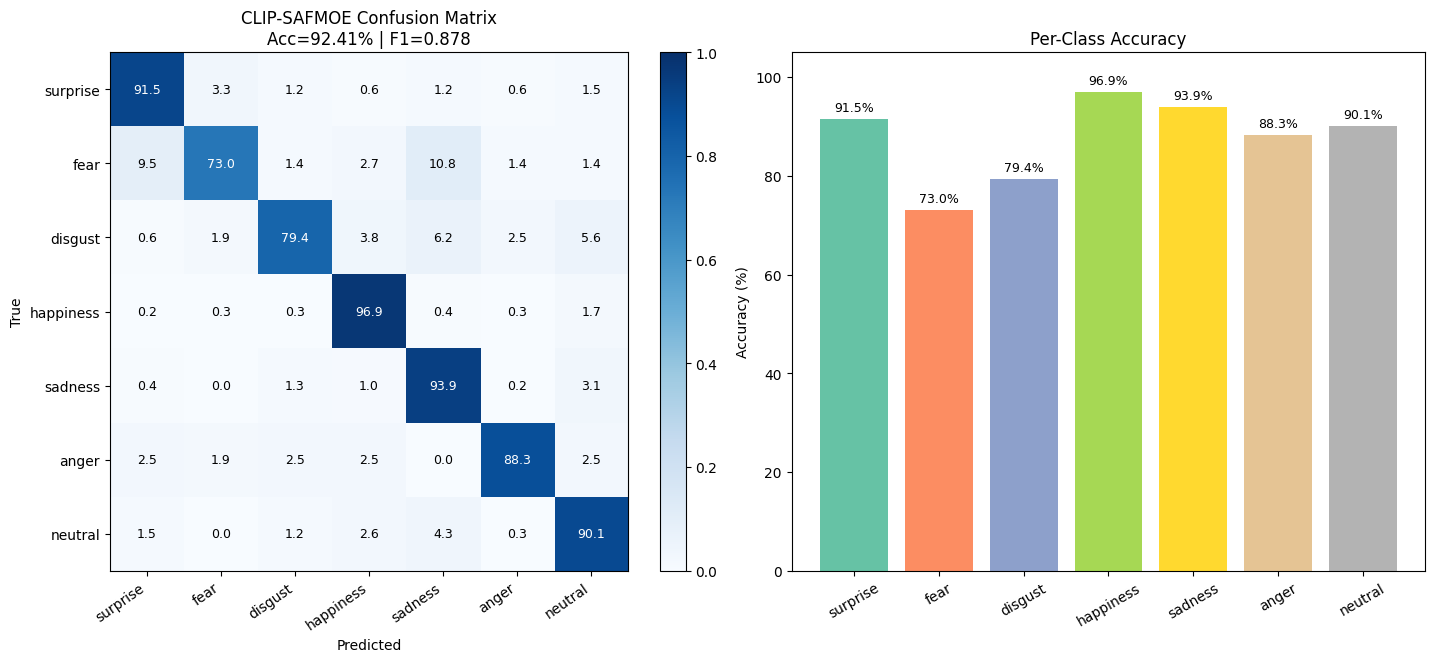

In [ ]:
# %% Cell 24: Confusion Matrix Visualization
cm = RESULTS["tta_cm"]
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

# Normalized confusion matrix
ax = axes[0]
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CFG.CLASS_NAMES, rotation=35, ha="right")
ax.set_yticklabels(CFG.CLASS_NAMES)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        v = cm_norm[i, j]
        ax.text(j, i, f"{v*100:.1f}", ha="center", va="center",
                color="white" if v > 0.5 else "black", fontsize=9)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"CLIP-SAFMOE Confusion Matrix\nAcc={TTA_ACC*100:.2f}% | F1={TTA_F1:.3f}")
plt.colorbar(im, ax=ax, fraction=0.046)

# Per-class accuracy bar chart
ax2 = axes[1]
per_class_acc = np.diag(cm_norm) * 100
colors = plt.cm.Set2(np.linspace(0, 1, NUM_CLASSES))
bars = ax2.bar(CFG.CLASS_NAMES, per_class_acc, color=colors)
ax2.set_ylim(0, 105)
ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Per-Class Accuracy")
ax2.tick_params(axis="x", rotation=30)
for bar, v in zip(bars, per_class_acc):
    ax2.text(bar.get_x() + bar.get_width()/2, v + 1, f"{v:.1f}%",
             ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(CFG.work_dir, "confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

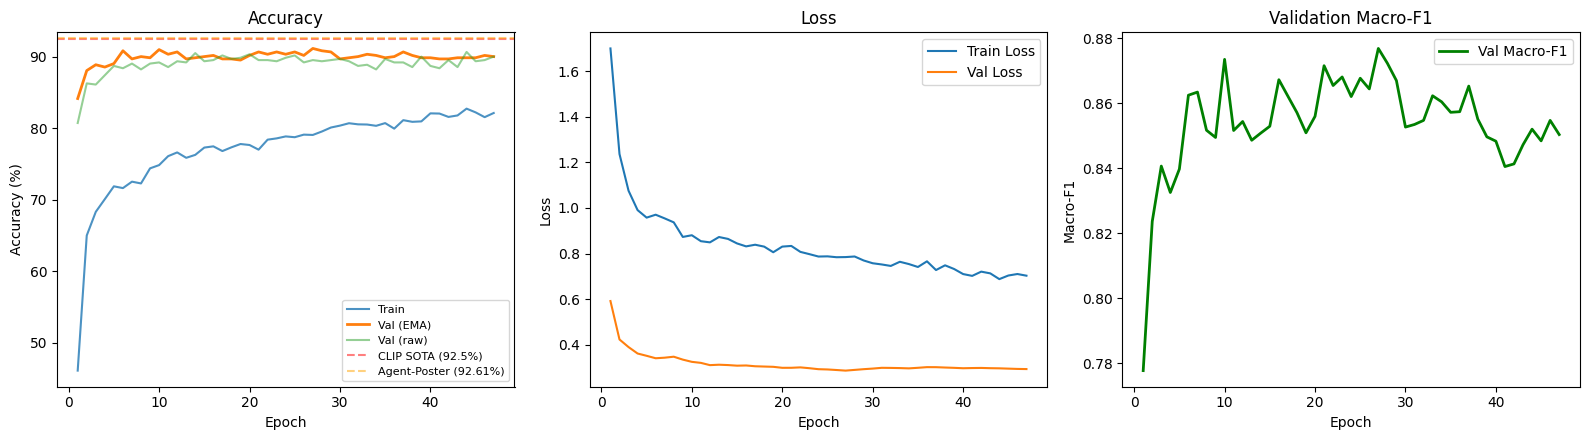

In [ ]:
# %% Cell 25: Training Curves
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

epochs_range = range(1, len(HISTORY["train_acc"]) + 1)

# Accuracy
axes[0].plot(epochs_range, [a*100 for a in HISTORY["train_acc"]], label="Train", alpha=0.8)
axes[0].plot(epochs_range, [a*100 for a in HISTORY["val_acc"]], label="Val (EMA)", linewidth=2)
axes[0].plot(epochs_range, [a*100 for a in HISTORY["raw_val_acc"]], label="Val (raw)", alpha=0.5)
axes[0].axhline(y=CFG.clip_sota_acc, color='red', linestyle='--', alpha=0.5, label=f"CLIP SOTA ({CFG.clip_sota_acc}%)")
axes[0].axhline(y=CFG.agent_poster, color='orange', linestyle='--', alpha=0.5, label=f"Agent-Poster ({CFG.agent_poster}%)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Accuracy"); axes[0].legend(fontsize=8)

# Loss
axes[1].plot(epochs_range, HISTORY["train_loss"], label="Train Loss")
axes[1].plot(epochs_range, HISTORY["val_loss"], label="Val Loss")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
axes[1].set_title("Loss"); axes[1].legend()

# F1
axes[2].plot(epochs_range, HISTORY["val_f1"], label="Val Macro-F1", color="green", linewidth=2)
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Macro-F1")
axes[2].set_title("Validation Macro-F1"); axes[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(CFG.work_dir, "training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# %% Cell 26: Save Predictions & Metrics
prob_cols = {f"p_{n}": RESULTS["tta_probs"][:, k] for k, n in enumerate(CFG.CLASS_NAMES)}
pred_df = pd.DataFrame({
    "filepath": RESULTS["filepaths"],
    "true_idx": RESULTS["tta_ytrue"],
    "true": [CFG.CLASS_NAMES[i] for i in RESULTS["tta_ytrue"]],
    "pred_idx": RESULTS["tta_preds"],
    "pred": [CFG.CLASS_NAMES[i] for i in RESULTS["tta_preds"]],
    **prob_cols,
})
pred_df.to_csv(PRED_CSV, index=False)

metrics_out = {
    "model": "CLIP-SAFMOE",
    "backbone": BACKBONE_USED,
    "novel_contributions": ["ASF", "SAM", "MoEE"],
    "best_val_acc": float(BEST_VAL_ACC),
    "best_epoch": int(BEST_EPOCH),
    "eval_split": "official_test" if RESULTS["is_official_test"] else "val_proxy",
    "eval_accuracy_tta": float(RESULTS["tta_acc"]),
    "eval_macro_f1_tta": float(RESULTS["tta_f1"]),
    "eval_accuracy_notta": float(RESULTS["notta_acc"]),
    "tta_views": len(TTA_VIEWS),
    "trainable_params_M": sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6,
    "total_params_M": sum(p.numel() for p in model.parameters()) / 1e6,
}
with open(METRICS_JSON, "w") as fh:
    json.dump(metrics_out, fh, indent=2)

print(f"Saved: {PRED_CSV}")
print(f"Saved: {METRICS_JSON}")

Saved: /kaggle/working/safmoe_output/predictions.csv
Saved: /kaggle/working/safmoe_output/metrics.json


In [ ]:
# %% Cell 27: Final Results
print("=" * 70)
print("CLIP-SAFMOE — FINAL RAF-DB RESULTS")
print("=" * 70)
print(f"Architecture             : CLIP-SAFMOE (Semantic-Adaptive Fusion + MoEE)")
print(f"Backbone                 : {BACKBONE_USED}")
print(f"Novel contributions      : ASF={CFG.use_asf} | SAM={CFG.use_sam} | MoEE={CFG.use_moee}")
print(f"Best validation accuracy : {BEST_VAL_ACC*100:.2f}%  (epoch {BEST_EPOCH})")
split_name = "Official RAF-DB test set" if RESULTS["is_official_test"] \
             else "Validation split (TEST PROXY)"
print(f"Evaluation split         : {split_name}")
print(f"Test/proxy accuracy      : {RESULTS['tta_acc']*100:.2f}%  ({len(TTA_VIEWS)}-view TTA)")
print(f"No-TTA accuracy          : {RESULTS['notta_acc']*100:.2f}%")
print(f"Macro F1                 : {RESULTS['tta_f1']:.4f}")

print("-" * 70)

# Comparison with baselines
print("\n--- COMPARISON WITH BASELINES ---")
baselines = [
    ("POSTER", CFG.poster_acc),
    ("POSTER++", CFG.poster_pp_acc),
    ("CLIP SOTA ref", CFG.clip_sota_acc),
    ("Agent-Poster", CFG.agent_poster),
]
our_acc = RESULTS["tta_acc"] * 100
for name, acc in baselines:
    beats = our_acc > acc
    diff = our_acc - acc
    print(f"  vs {name:16s} ({acc:.2f}%) : {'✓ BEATS' if beats else '✗ below'} "
          f"({diff:+.2f} pts)")

print("=" * 70)

if our_acc > CFG.clip_sota_acc:
    print(f"\n🎉 CLIP-SAFMOE EXCEEDS CLIP SOTA ({CFG.clip_sota_acc}%) with {our_acc:.2f}%!")
if our_acc > CFG.agent_poster:
    print(f"🏆 CLIP-SAFMOE EXCEEDS Agent-Poster ({CFG.agent_poster}%) — NEW SOTA!")
print()

# Per-class breakdown
print("--- PER-CLASS BREAKDOWN ---")
print(f"{'Class':12s} {'Acc':>7s} {'Prec':>7s} {'Rec':>7s} {'F1':>7s} {'Support':>8s}")
for i in range(NUM_CLASSES):
    print(f"{CFG.CLASS_NAMES[i]:12s} {np.diag(cm_norm)[i]*100:6.1f}% "
          f"{TTA_PREC[i]*100:6.1f}% {TTA_REC[i]*100:6.1f}% "
          f"{TTA_F1C[i]*100:6.1f}% {int(TTA_SUP[i]):7d}")